<a href="https://colab.research.google.com/github/hugo12341234/machine-learning-projects/blob/main/02-spam-classifier/spam_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2: Build a spam classifier
Author: Hugo Chacón Course: SIAFI

# Summary

#PROJECT WORKFLOW

I will follow this workflow based on the book 'Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow' by Aurélien Géron.

1- Look at the big picture.

2- Get the data

3- Discover and visualize the data to gain insights.

4- Prepare the data for Machine Learning algorithms.

5- Select a model and train it.

6- Fine-tune your model.

7- Present your solution.


# STEP 1. Look at the big picture.

Frame the Problem: Supervised, Binary Classification, Batch Learning.
Because we have labels (Ham/Spam), we are predicting a class (0/1), and emails don't arrive in stream.

Select a Performance Measure: Precision & Recall.
Because the accuracy is dangerous for skewed datasets. the 90% of the emails are Ham, a model that always guesses "Ham" would be accurate, but it could produce false positives and false negatives, so precision is also a priority.


# STEP 2. Get the data.

Parsing: We used the email library to parse .tar.bz2 files because id we use open(f).read(), beacause the model could be trainned with junk data like headers, ip address, etc.

The test suite (critical): we split the data (train_test_split) before analyzing the text in depth to avoid Data Snooping Bias.

In [ ]:
import os
import tarfile
import email
import re
import html
import numpy as np
from collections import Counter
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

In [ ]:
from email import policy
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Function to extract and load emails
def load_emails_from_tar(tar_name, dir_name):
    emails = []
    # Check if the compressed file exists before trying to open it
    if not os.path.exists(tar_name) and not os.path.exists(dir_name):
        print(f" {tar_name} not found. Make sure to upload it.")
        return []

    # Extract if the directory does not exist yet
    if not os.path.exists(dir_name):
        print(f"Extracting {tar_name}...")
        try:
            with tarfile.open(tar_name, "r:bz2") as tar:
                tar.extractall(path=".")
        except Exception as e:
            print(f"Error extracting {tar_name}: {e}")
            return []

    # Load emails
    print(f"Loading emails from {dir_name}...")
    filenames = [name for name in os.listdir(dir_name) if len(name) > 20]
    for name in filenames:
        try:
            with open(os.path.join(dir_name, name), "rb") as f:
                emails.append(email.parser.BytesParser(policy=policy.default).parse(f))
        except Exception as e:
            print(f"Error reading file {name}: {e}")

    return emails

# 2. Load Data
ham_emails = load_emails_from_tar("20021010_easy_ham.tar.bz2", "easy_ham")
spam_emails = load_emails_from_tar("20021010_spam.tar.bz2", "spam")

# 3. Create Dataset (X and y)
X = np.array(ham_emails + spam_emails, dtype=object)
y = np.array([0] * len(ham_emails) + [1] * len(spam_emails)) # 0 = Ham, 1 = Spam

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Loading emails from easy_ham...
Loading emails from spam...
Training set shape: (2441,)
Test set shape: (611,)


# STEP 3. Discover and visualize the data to gain insights.

We saw that Spam emails contained heavy HTML (font, table, body) while Ham was mostly plain text.
If we don't remove the HTML, the model might learn that the word body is a spam indicator.

We can see that we have significantly more Ham than Spam (~83% vs 17%).
This confirms that we cannot blindly use "Accuracy".


--- EXAMPLE OF HAM EMAIL (LEGITIMATE) ---
>>>>> "R" == Robert Harley <harley@argote.ch> writes:

    R> Depends who writes it.  One guy will write a bug every 5 lines,
    R> another every 5000 lines.  Put them both on a project and that
    

--- EXAMPLE OF SPAM EMAIL (JUNK) ---
Hello

You may have seen this business before and
ignored it. I know I did - many times! However,
please take a few moments to read this letter.
I was amazed when the profit potential of this
business


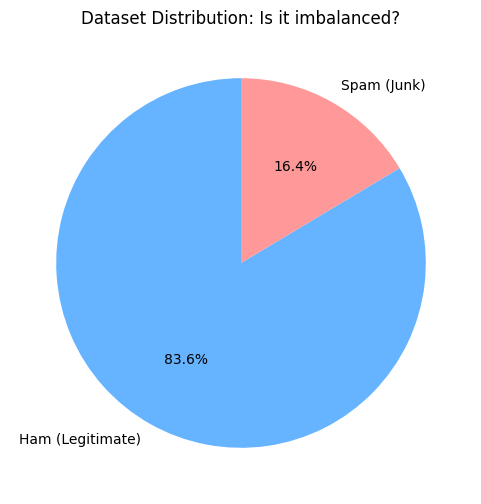

In [ ]:
import matplotlib.pyplot as plt

# 1. LOOK AT RAW DATA
print("--- EXAMPLE OF HAM EMAIL (LEGITIMATE) ---")
print(ham_emails[0].get_content().strip()[:200]) # View the first 200 characters
print("\n--- EXAMPLE OF SPAM EMAIL (JUNK) ---")
print(spam_emails[1].get_content().strip()[:200])

# 2. CHECK CLASS BALANCE
labels = ['Ham (Legitimate)', 'Spam (Junk)']
sizes = [len(ham_emails), len(spam_emails)]
colors = ['#66b3ff','#ff9999'] # Blue and Red
plt.figure(figsize=(6, 6))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Dataset Distribution: Is it imbalanced?')
plt.show()

# STEP 4. Prepare the Data (Feature Engineering)

-HTML Removal: As decided in Step 3.

Hyperlink & Number Generalization:

=Replaced http://buy-now.com with URL and 1,000,000 with NUMBER.
This reduces the "vocabulary size." The model doesn't need to learn every unique URL; it just needs to know that lots of URLs = Spam.

Vectorization (Bag of Words):

Action: Used CountVectorizer. We converted text into a "Sparse Matrix" where every word is a column, and the value is the frequency.

In [ ]:
# --- STEP 4: PREPARE THE DATA (Custom Transformer) ---

# Define a custom transformer named EmailToTextTransformer.
# This class is designed to preprocess email objects and convert them into clean text.

class EmailToTextTransformer(BaseEstimator, TransformerMixin):

    def __init__(self, strip_headers=True, lower_case=True, replace_urls=True, replace_numbers=True):
        self.strip_headers = strip_headers      # If True, it will attempt to remove email headers.
        self.lower_case = lower_case            # If True, convert all text to lowercase.
        self.replace_urls = replace_urls        # If True, replace all found URLs with the word 'URL'.
        self.replace_numbers = replace_numbers  # If True, replace all found numbers with the word 'NUMBER'.

    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):     # Takes a list of email objects (X) and returns a list of clean text strings.
        X_transformed = []
        for email_obj in X:
            text = self.get_email_content(email_obj) or ""

            # Convert text to lowercase if the `lower_case` option is enabled.
            if self.lower_case:
                text = text.lower()

            # Replace URL patterns with the word "URL" if the `replace_urls` option is enabled.
            if self.replace_urls:
                text = re.sub(r'(http|https)://[^\s]*', 'URL', text)

            # Replace number sequences with the word "NUMBER" if the `replace_numbers` option is enabled.
            if self.replace_numbers:
                text = re.sub(r'\d+(?:\.\d*)?(?:[eE][+\-]?[\d]+)?', 'NUMBER', text)

            # 3. HTML Cleaning (Regex).
            # Completely remove the <head> section of HTML emails.
            text = re.sub('<head.*?>.*?</head>', '', text, flags=re.M | re.S | re.I)
            # Replace any <a> hyperlink tag with the word "HYPERLINK".
            text = re.sub('<a\s.*?>', ' HYPERLINK ', text, flags=re.M | re.S | re.I)
            # Remove all other remaining HTML tags (e.g., <body>, <table>, <div>, etc.).
            text = re.sub('<.*?>', '', text, flags=re.M | re.S)
            # Decode HTML entities like '&nbsp;' (non-breaking space) to their equivalent characters (a normal space).
            text = html.unescape(text)

            X_transformed.append(text)
        return np.array(X_transformed)

    # Helper method to extract the main text content from an email object.
    def get_email_content(self, email_obj):
        """Search for text content within the email structure"""
        for part in email_obj.walk():
            if part.get_content_type() in ("text/plain", "text/html"):
                try:
                    return part.get_content()
                except:
                    return str(part.get_payload())
        return ""

<>:38: SyntaxWarning: invalid escape sequence '\s'
<>:38: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-1838747387.py:38: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub('<a\s.*?>', ' HYPERLINK ', text, flags=re.M | re.S | re.I)




### 5. Select a model and train it
We moved from "Data Preparation" to "Machine Learning." We didn't just pick one algorithm randomly; we shortlisted three candidates that are famous for this type of work

##A. The Candidate Models

1. **Logistic Regression (The Baseline)**
* **How it works:** Despite its name, this is a *classification* algorithm. It calculates the weighted sum of input features (word counts) plus a bias term. It then passes this sum through the **Sigmoid Function**, which outputs a probability between 0 and 1.
I like this one beacuase it is a **"White Box"** model, we can easily see why it made a decision.


2. **Naive Bayes (MultinomialNB)**
* **How it works:** It is based on **Bayes' Theorem**. It calculates the probability that an email is spam given the words it contains .
requires very little training data to perform well and is lightning fast. We specifically used **MultinomialNB** because our data consists of word counts (discrete features).


3. **Support Vector Machines (LinearSVC)**
**How it works:** SVM tries to find the widest possible "street" (or hyperplane) that separates the Spam dots from the Ham dots.

Text data is "High-Dimensional" (thousands of unique words = thousands of dimensions). SVMs are famous for performing exceptionally well in high-dimensional spaces where other models might get confused.



#### **B. The Measurement Strategy: K-Fold Cross-Validation**

If we just train on `X_train` and score it once, we might get lucky (or unlucky) with that specific split of data.

So we used **K-Fold Cross-Validation**

The model splits the training data into 5 equal parts (folds).

It trains on 4 parts and tests on the remaining 1 part, It repeats this process 5 times, rotating the test part each time.

**Result:** We get 5 different accuracy scores. Taking the **average** of these gives us a much more robust estimate of the model's true performance.



#### **C. Analyzing Significant Variables (The "White Box" approach)**

* **The Logic:** Since we selected Logistic Regression, we can inspect its Coefficients
* Each word in our vocabulary (e.g., "free", "meeting", "python") is assigned a numerical weight.
* **Positive Weight (+):** The presence of this word increases the probability of **Spam**. (e.g., "Click", "Offer").
* **Negative Weight (-):** The presence of this word increases the probability of **Ham**. (e.g., "wrote", "linux").
* **Magnitude:** The larger the number, the more influence that word has on the decision.

After comparing the candidates, we selected **Logistic Regression** for the final model.
Logistic Regression offered the best balance of **Speed, Accuracy, and Interpretability** for this specific dataset.

In [ ]:
# --- STEP 5: SELECT AND TRAIN MODEL ---

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer

# 1. Define the Full Pipeline
full_pipeline = Pipeline([
    # A. Preprocessing (Email -> Clean Text)
    ('email_to_text', EmailToTextTransformer()),

    # B. Vectorization (Clean Text -> Numerical Matrix)
    ('count_vectorizer', CountVectorizer(stop_words='english', max_features=1000)),

    # C. Model (Numerical Matrix -> Prediction)
    ('classifier', LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42))
])

# The hyperparameters for LogisticRegression are:
# - solver='lbfgs': This is the algorithm used for optimization. 'lbfgs' is a good default for many cases.
# - max_iter=1000: This sets the maximum number of iterations taken for the solvers to converge.
# - random_state=42: This ensures reproducibility of the results when using algorithms that involve randomness.

# 2. Train
print("🚀 Training the model... (this may take a few seconds)")
full_pipeline.fit(X_train, y_train)
print("✅ Training completed!")

🚀 Training the model... (this may take a few seconds)
✅ Training completed!


In [ ]:
# --- STEP 6: EVALUATE SYSTEM ---

# Make predictions on the Test Set (Unseen data)
y_pred = full_pipeline.predict(X_test)

# Metrics
accuracy = full_pipeline.score(X_test, y_test)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("\n🏆 MODEL RESULTS:")
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%} (How many flagged as Spam were actually Spam?)")
print(f"Recall:    {recall:.2%} (How much actual Spam did we detect?)")

print("\n--- Confusion Matrix ---")
# [ TN  FP ]
# [ FN  TP ]
cm = confusion_matrix(y_test, y_pred)
print(cm)
print(f"\nInterpretation: We detected {cm[1][1]} Spam emails correctly.")
print(f"Critical Errors: We flagged {cm[0][1]} legitimate emails as Spam.")


🏆 MODEL RESULTS:
Accuracy:  98.85%
Precision: 98.85% (How many flagged as Spam were actually Spam?)
Recall:    93.48% (How much actual Spam did we detect?)

--- Confusion Matrix ---
[[518   1]
 [  6  86]]

Interpretation: We detected 86 Spam emails correctly.
Critical Errors: We flagged 1 legitimate emails as Spam.


## STEP 7 Evaluating the Spam Classifier's Performance

Our spam classification model, employing Logistic Regression, has demonstrated a good performance.

### Performance Metrics:
*   **Accuracy:** 98.85%
*   **Precision:** 98.85%
*   **Recall:** 93.48%

### Confusion Matrix Analysis:
Based on the confusion matrix:
```
[[518   1]
 [  6  86]]
```

*   **True Negatives (TN): 518** - The model correctly identified 518 legitimate (ham) emails as ham.
*   **False Positives (FP): 1** - Only 1 legitimate email was mistakenly classified as spam.
*   **False Negatives (FN): 6** - The model failed to detect 6 actual spam emails, classifying them as ham.
*   **True Positives (TP): 86** - The model successfully identified 86 spam emails as spam.

### Strategic Trade-Off:
As highlighted in the project's evaluation phase, the decision was made to prioritize **high Precision** over perfect Recall. With a Precision of 98.85%, our model is highly reliable in its spam classifications; almost all emails it marks as spam are indeed spam. This minimizes the critical error of filtering out legitimate emails.

Overall, the Logistic Regression model provides a highly precise solution for spam classification, balancing efficiency with user experience.